In [1]:
%pip install kagglehub

Note: you may need to restart the kernel to use updated packages.


In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Timoteo\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?


In [2]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np 


In [4]:
amazon_uk_prices = pd.read_csv(r"C:\Users\Timoteo\OneDrive\Documents\Iron_Hack\Week_2\Labs\D4\lab-eda-univariate\amz_uk_price_prediction_dataset.csv")

In [5]:
amazon_uk_prices.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [36]:
amazon_uk_prices.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [52]:
amazon_uk_prices.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [38]:
amazon_uk_prices["category"].describe()

count               2443651
unique                  296
top       Sports & Outdoors
freq                 836265
Name: category, dtype: object

In [39]:
num = amazon_uk_prices.select_dtypes(include="number") 
cat = amazon_uk_prices.select_dtypes(exclude="number")

In [41]:
num.head()

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0


In [42]:
cat.head()

,asin,title,isBestSeller,category
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",False,Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",True,Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",False,Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",False,Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,False,Hi-Fi Speakers


In [43]:
category_freq = cat["category"].value_counts().reset_index()
category_freq.columns = ["Category", "Count"]

category_freq

,Category,Count
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978
...,...,...
291,Motorbike Chassis,107
292,Alexa Built-In Devices,107
293,Plugs,107
294,Smart Home Security & Lighting,104


In [44]:
category_freq.head(5)


,Category,Count
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


C:\Users\Timoteo\AppData\Local\Temp\ipykernel_20700\2527904128.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


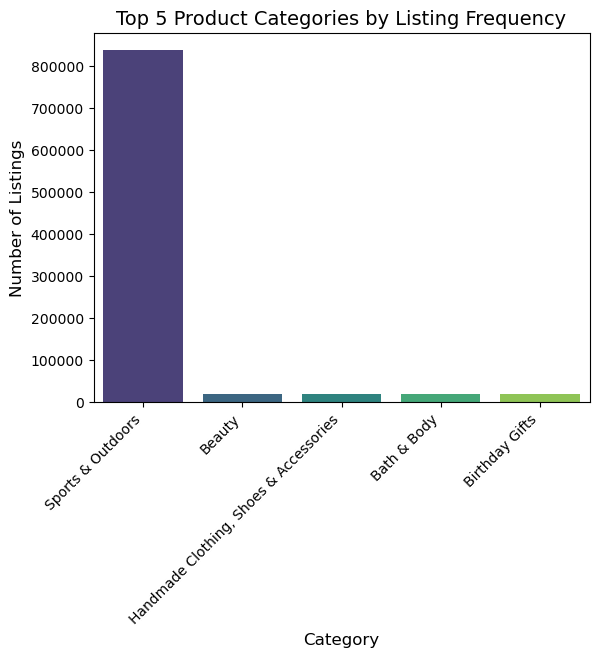

In [45]:
# Bar Chart - Top 5 product

top5 = category_freq.head(5)

sns.barplot(
    x="Category", 
    y='Count', 
    data=top5, 
    palette='viridis',
    legend=True,
)
plt.title('Top 5 Product Categories by Listing Frequency', fontsize=14)
plt.xlabel('Category', fontsize=12)
plt.ylabel('Number of Listings', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.show()

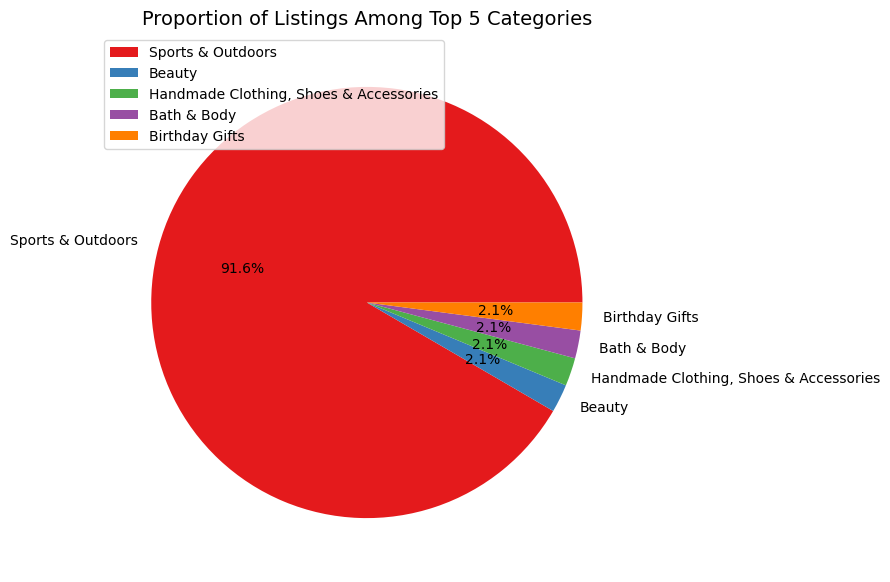

In [46]:
# Pie chart - proportions

top5.plot.pie(
    y='Count',
    labels=top5['Category'],
    autopct='%1.1f%%',
    colors=sns.color_palette('Set1'),
    figsize=(7,7)
)

plt.title('Proportion of Listings Among Top 5 Categories', fontsize=14)
plt.ylabel('')  # Removes unnecessary y-label
plt.show()

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 


In [ ]:
price_mean = round(float(num["price"].mean()), 1)
price_median = round(float(num["price"].median()), 2)
price_mode = num["price"].mode()

price_mean, price_median, price_mode

(89.2,
 19.09,
 0    9.99
 Name: price, dtype: float64)

In [74]:
price_var = round(float(num["price"].var()), 2)
price_std = round(float(num["price"].std()), 2)
price_var, price_std

(119445.49, 345.61)

In [79]:
q1 = int(num.price.quantile(0.75))
q3 = int(num.price.quantile(0.25))

price_range = num["price"].max() - num["price"].min()

price_interquartile = int(num.price.quantile(0.75)-num.price.quantile(0.25))

q1, q3, price_range, price_interquartile


(45, 9, 100000.0, 36)

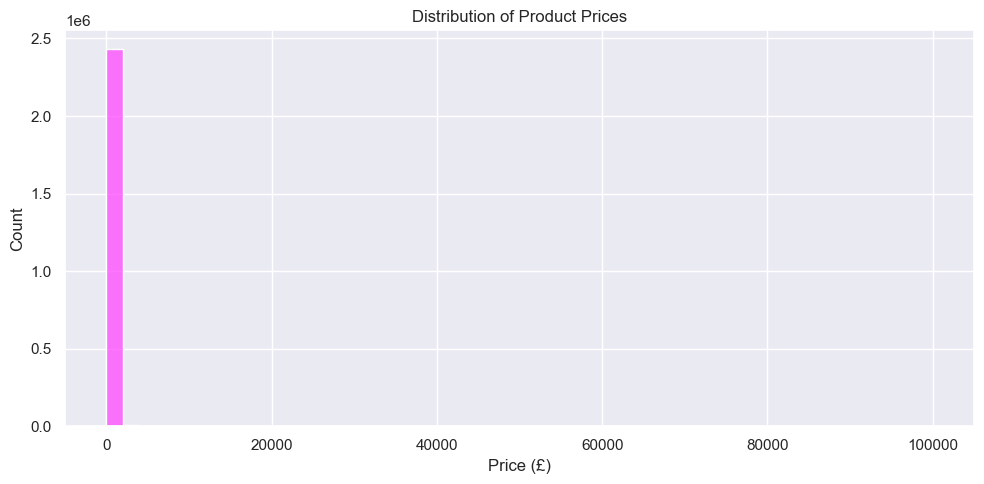

In [103]:
plt.figure(figsize=(10,5))
sns.histplot(num["price"], bins=50, color ="#FF47FF", kde=False)
plt.title('Distribution of Product Prices')
plt.xlabel('Price (£)')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

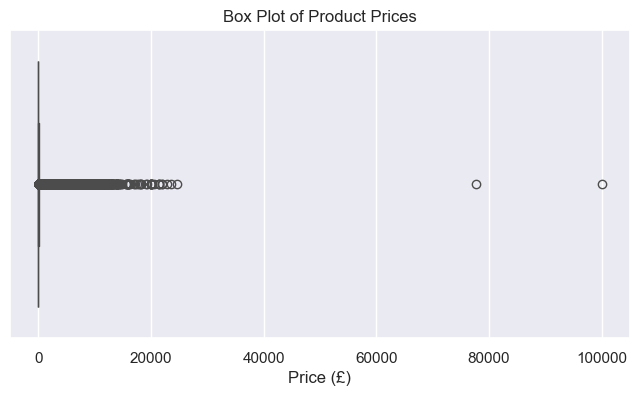

In [88]:
plt.figure(figsize=(8,4))
sns.boxplot(x=num["price"])
plt.title('Box Plot of Product Prices')
plt.xlabel('Price (£)')
plt.show()

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [89]:
stars_mean = round(float(num["stars"].mean()), 1)
stars_median = round(float(num["stars"].median()), 2)
stars_mode = num["stars"].mode()

stars_mean, stars_median, stars_mode

(2.2,
 0.0,
 0    0.0
 Name: stars, dtype: float64)

In [90]:
stars_var = round(float(num["stars"].var()), 2)
stars_std = round(float(num["stars"].std()), 2)
stars_var, stars_std

(4.82, 2.19)

In [ ]:
num["stars"].skew()
rating_skw = round(float(num["stars"].skew()), 2)
rating_skw


np.float64(0.08120735761080985)

In [102]:
num["stars"].kurtosis()
rating_kurt = round(float(num["stars"].kurtosis()), 2)
rating_kurt

-1.93

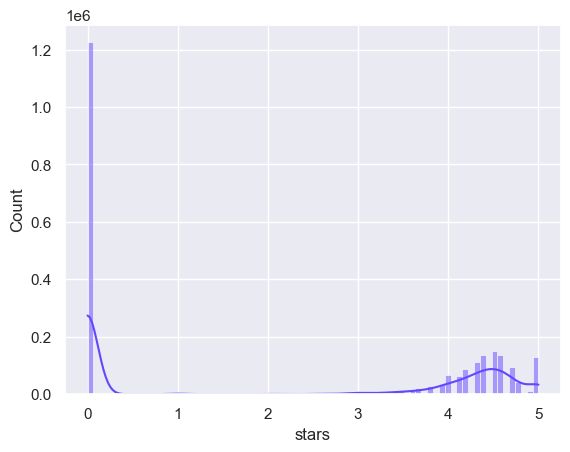

In [101]:
sns.histplot(num.stars, bins="auto", color="#6347FF", kde=True)
plt.show()